# Random Forest — v2
**Notebook independiente · Entrenamiento y evidencia para 6.1–6.4**

Adjunta el **ZIP completo** generado por 00_preparacion_insumos_v2 como dataset de Kaggle. El lector busca el contrato interno, admite el ZIP histórico preparado y el ZIP v2; comprueba su contenido antes de entrenar. No requiere extracción manual ni ejecución de otro modelo.

La detección automática exige una sola preparación completa. Si hay varias, fija `prepared_zip` o `prepared_root`. El ZIP de reportes/diagnóstico no cumple el contrato.

Selección por CV agrupada en train, umbral por OOF y validación fija posterior. LSSiren permanece reservado para la evaluación externa. Misma semilla y mismo ZIP en todos los modelos.

Logs: barra de progreso, eventos por candidato/fold, heartbeat durante ajustes largos, CSV y JSONL persistentes. En redes hay detalle por batch/época, pérdidas, F1, recall, LR, paciencia y memoria GPU; TensorBoard si está instalado. Los logs no requieren servicios externos.


## 0. Configuración

Puedes dejar prepared_root y prepared_zip en None si solo hay un paquete completo. Para seleccionar uno explícito, usa la ruta al ZIP en prepared_zip. Revisa el presupuesto de candidatos antes de observar validation.

In [1]:
CFG = {'seed': 42,
 'prepared_root': None,
 'search_roots': ['/kaggle/input'],
 'output_base': '/kaggle/working/entrenamiento',
 'metadata_file': 'metadata/metadata_segments.csv',
 'file_metadata_file': None,
 'preparation_config': 'config/preparation_config.json',
 'split_files': {'train': 'splits/train.csv',
                 'validation': 'splits/validation.csv',
                 'generalization': 'splits/generalization.csv'},
 'column_map': {},
 'label_map': {'NON_EMERGENCY': 0, 'EMERGENCY': 1},
 'dataset_aliases': {'AudioSet-EV': 'AudioSet-EV v2',
                     'audioset-ev': 'AudioSet-EV v2',
                     'audioset_ev': 'AudioSet-EV v2',
                     'sirennet': 'sireNNet',
                     'SireNNet': 'sireNNet',
                     'a3s-rec': 'A3Siren-Recordings',
                     'A3Siren': 'A3Siren-Recordings',
                     'lssiren': 'LSSiren'},
 'development_corpora': ['AudioSet-EV v2', 'sireNNet', 'A3Siren-Recordings'],
 'holdout_corpus': 'LSSiren',
 'additional_group_columns': ['source_video_id', 'original_recording_id', 'augmentation_parent_id'],
 'require_original_group_column': None,
 'cv_folds': 3,
 'target_recall': 0.9,
 'target_fpr': 0.1,
 'bootstrap_repeats': 500,
 'cpu_workers': 2,
 'latency_warmup': 20,
 'latency_repeats': 100,
 'throughput_batch': 2048,
 'feature_files': ['features/acoustic_features.csv', 'features/mfcc_features.csv'],
 'features_are_unscaled': True,
 'feature_columns': ['rms',
                     'zcr',
                     'dominant_frequency',
                     'spectral_centroid',
                     'spectral_bandwidth',
                     'spectral_rolloff',
                     'spectral_flux',
                     'spectral_flatness',
                     'mfcc_1',
                     'mfcc_2',
                     'mfcc_3',
                     'mfcc_4',
                     'mfcc_5',
                     'mfcc_6',
                     'mfcc_7',
                     'mfcc_8',
                     'mfcc_9',
                     'mfcc_10',
                     'mfcc_11',
                     'mfcc_12',
                     'mfcc_13'],
 'feature_column_map': {'dominant_frequency_hz': 'dominant_frequency',
                        'spectral_centroid_hz': 'spectral_centroid',
                        'spectral_bandwidth_hz': 'spectral_bandwidth',
                        'spectral_rolloff_hz': 'spectral_rolloff'},
 'max_iter': 5000,
 'model_name': '02_random_forest_v2',
 'display_name': 'Random Forest',
 'model_kind': 'rf',
 'candidates': [{'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
                {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
                {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt'}],
 'prepared_zip': None,
 'prepared_cache': '/kaggle/working/prepared_cache_v2',
 'unzip_reserve_gib': 2.0,
 'heartbeat_seconds': 30,
 'tensorboard': True,
 'batch_log_every': 100}


## 1. Dependencies

Dependencias del modelo y utilidades.

In [2]:
import os, sys, json, time, hashlib, platform, shutil, random, warnings, subprocess, gc
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from sklearn.exceptions import ConvergenceWarning
try:
    from IPython.display import display
except ImportError:
    def display(value): print(value)



## 2. Io environment

Salida única por ejecución; versiones y hardware registrados.

In [3]:
def jsonable(x):
    if isinstance(x, (np.integer, np.floating)): return x.item()
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, Path): return str(x)
    raise TypeError(type(x).__name__)

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=jsonable), encoding='utf-8')
    tmp.replace(path)

def sha_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

def save_table(name, rows):
    data = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    data.to_csv(OUT/'tables'/name, index=False)
    return data

def fail(message):
    write_json(OUT/'reports'/'failure.json', {'status':'BLOCKED', 'message':str(message)})
    import zipfile
    diagnostic = OUT.parent/(OUT.name+'_diagnostico.zip')
    with zipfile.ZipFile(diagnostic,'w',zipfile.ZIP_DEFLATED) as z:
        for folder in ['config','reports','tables']:
            for p in (OUT/folder).rglob('*'):
                if p.is_file(): z.write(p,str(p.relative_to(OUT)))
    print('Diagnóstico:', diagnostic)
    raise ValueError(message)

def environment():
    packages = {}
    for name in ['numpy','pandas','scikit-learn','scipy','matplotlib','joblib','torch','torchvision']:
        try: packages[name] = version(name)
        except PackageNotFoundError: packages[name] = None
    try:
        gpu = subprocess.run(['nvidia-smi','--query-gpu=name,memory.total,driver_version',
                              '--format=csv,noheader'], capture_output=True, text=True, timeout=10).stdout.strip()
    except (FileNotFoundError, subprocess.SubprocessError): gpu = 'No detectada'
    try: ram = int(next(l.split()[1] for l in Path('/proc/meminfo').read_text().splitlines() if l.startswith('MemTotal:')))*1024
    except Exception: ram = None
    return {'python':sys.version, 'platform':platform.platform(), 'packages':packages,
            'cpu_count':os.cpu_count(), 'ram_bytes':ram, 'gpu_nvidia_smi':gpu,
            'disk_free_bytes':shutil.disk_usage(OUT).free}

random.seed(CFG['seed']); np.random.seed(CFG['seed'])
OUTPUT_BASE = Path(CFG['output_base']).resolve()
if str(OUTPUT_BASE).startswith('/kaggle/input'):
    raise ValueError('La salida nunca puede ubicarse dentro de /kaggle/input.')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = OUTPUT_BASE / CFG['model_name'] / RUN_ID
for folder in ['config','tables','figures','reports','models','predictions','checkpoints','logs']:
    (OUT/folder).mkdir(parents=True, exist_ok=True)
START_TIME = time.perf_counter()
write_json(OUT/'config'/'training_config.json', CFG)
ENV = environment(); write_json(OUT/'reports'/'environment.json', ENV)
display(pd.DataFrame([{'modelo':CFG['model_name'],'salida':str(OUT),'CPU':ENV['cpu_count'],
                       'GPU':ENV['gpu_nvidia_smi']}]))



,modelo,salida,CPU,GPU
0,02_random_forest_v2,/kaggle/working/entrenamiento/02_random_forest...,4,No detectada


### Registro de la ejecución

Los errores se guardan con traceback y ZIP diagnóstico.

In [4]:
# %% logging_runtime
import logging, traceback, threading
from contextlib import contextmanager
try:
    from tqdm.auto import tqdm
except ImportError:
    class tqdm:
        def __init__(self, iterable=None, total=None, **kwargs):self.iterable=iterable
        def __iter__(self):return iter(self.iterable)
        def update(self,*args,**kwargs):pass
        def set_postfix(self,*args,**kwargs):pass
        def close(self):pass
try:
    import psutil
except ImportError:
    psutil=None
LOG_DIR=OUT/'logs';LOG_DIR.mkdir(exist_ok=True)
LOGGER=logging.getLogger('doppler.'+str(OUT));LOGGER.setLevel(logging.INFO);LOGGER.propagate=False
for h in LOGGER.handlers[:]:h.close();LOGGER.removeHandler(h)
handler=logging.FileHandler(LOG_DIR/'training.log',encoding='utf-8');handler.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
LOGGER.addHandler(handler)
console=logging.StreamHandler(sys.stdout);console.setFormatter(logging.Formatter('%(asctime)s | %(message)s',datefmt='%H:%M:%S'));LOGGER.addHandler(console)

def resource_snapshot():
    if psutil:return {'rss_mib':psutil.Process().memory_info().rss/1024**2}
    return {}

def event(kind, console=True, **fields):
    record={'timestamp_utc':datetime.now(timezone.utc).isoformat(),'event':kind,**resource_snapshot(),**fields}
    with open(LOG_DIR/'events.jsonl','a',encoding='utf-8') as f:f.write(json.dumps(record,ensure_ascii=False,default=str)+'\n')
    if console:LOGGER.info('%s | %s',kind,' | '.join(f'{k}={v:.5g}' if isinstance(v,float) else f'{k}={v}' for k,v in fields.items()))

def diagnostic_bundle():
    import zipfile
    target=OUT.parent/(OUT.name+'_diagnostico.zip')
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED) as z:
        for folder in ['config','reports','tables','logs','metadata']:
            for p in (OUT/folder).rglob('*'):
                if p.is_file():z.write(p,str(p.relative_to(OUT)))
    return str(target)

@contextmanager
def stage_guard(name):
    tick=time.perf_counter();event('stage_start',stage=name)
    try:yield
    except BaseException as exc:
        error=traceback.format_exc();(LOG_DIR/'traceback.txt').write_text(error,encoding='utf-8')
        event('stage_failed',stage=name,error=str(exc),seconds=time.perf_counter()-tick)
        write_json(OUT/'reports/run_status.json',{'status':'FAILED','stage':name,'error':str(exc)})
        try:print('Diagnóstico guardado:',diagnostic_bundle())
        except Exception as diag_exc:print('No se pudo comprimir el diagnóstico:',diag_exc)
        raise
    else:event('stage_end',stage=name,seconds=time.perf_counter()-tick)

@contextmanager
def heartbeat(phase,**fields):
    stop=threading.Event();tick=time.perf_counter()
    def worker():
        while not stop.wait(CFG.get('heartbeat_seconds',30)):
            event('fit_running',phase=phase,elapsed_seconds=time.perf_counter()-tick,**fields)
    thread=threading.Thread(target=worker,daemon=True);thread.start()
    try:yield
    finally:stop.set();thread.join(timeout=1)

write_json(OUT/'reports/run_status.json',{'status':'RUNNING'})
event('run_start',model=CFG.get('model_name','preparation'),output=str(OUT))


03:48:54 | run_start | model=02_random_forest_v2 | output=/kaggle/working/entrenamiento/02_random_forest_v2/20261010T034849_698618Z


## 3. Data adapters

ZIP o carpeta, extracción segura y selectiva. Alias de metadata y contrato por segment_id.

In [5]:
with stage_guard('data_adapters'):
    ALIASES = {
     'segment_id':['segment_id','segment_uid'],
     'dataset':['dataset','corpus','dataset_name'],
     'file_id':['file_id','source_file_id'],
     'track_id':['track_id','source_track_id'],
     'canonical_label':['canonical_label','label_binary','target_label'],
     'original_label':['original_label','label_original'],
     'split':['split','partition','subset'],
     'sha256':['sha256','source_sha256'],
     'original_path':['original_path','source_path'],
     'representation_path':['representation_path','path_to_representation','logmel_path','spectrogram_path'],
    }

    def canonicalize(df):
        # Las equivalencias adicionales se especifican como {columna_original: columna_canónica}.
        df = df.rename(columns=CFG['column_map']).copy()
        if df.columns.duplicated().any(): fail('El mapeo de columnas crea nombres duplicados.')
        for canonical, variants in ALIASES.items():
            found = [c for c in variants if c in df]
            if canonical not in df and len(found)==1: df = df.rename(columns={found[0]:canonical})
            elif canonical not in df and len(found)>1: fail(f'Columnas ambiguas para {canonical}: {found}')
        return df

    def read_csv(path):
        df = pd.read_csv(path, dtype=str, keep_default_na=False)
        return canonicalize(df)

    def zip_contract(path):
        import zipfile
        try:
            with zipfile.ZipFile(path) as z:
                names=set(z.namelist())
                roots=[n[:-len('metadata/metadata_segments.csv')] for n in names if n.endswith('metadata/metadata_segments.csv')]
                roots=[r for r in roots if all(r+k in names for k in ['features/acoustic_features.csv','features/mfcc_features.csv',
                       'splits/train.csv','splits/validation.csv','splits/generalization.csv','config/preparation_config.json'])]
                if len(roots)==1:return roots[0]
        except (OSError,zipfile.BadZipFile):return None
        return None

    def unpack_prepared(path,prefix):
        import zipfile, stat
        from pathlib import PurePosixPath
        branch='deep' if CFG['model_kind'] in ['cnn','resnet'] else 'tabular'
        event('zip_hash_start',path=str(path))
        with heartbeat('zip_sha256'): fingerprint=sha_file(path)
        cache=Path(CFG['prepared_cache']).resolve()
        if cache==Path('/kaggle/input') or Path('/kaggle/input') in cache.parents:fail('prepared_cache debe estar fuera de /kaggle/input.')
        cache.mkdir(parents=True,exist_ok=True);destination=cache/(fingerprint[:20]+'_'+branch)
        marker=destination/'EXTRACTION_COMPLETE.json'
        if marker.is_file():
            saved=json.loads(marker.read_text())
            if saved.get('zip_sha256')==fingerprint and all((destination/p).is_file() and (destination/p).stat().st_size==size for p,size in saved['members'].items()):
                event('zip_cache_reused',root=str(destination));return destination
            fail('La extracción previa está incompleta o cambió. Usa otra prepared_cache para volver a extraer.')
        if destination.exists():fail('Existe una extracción parcial: usa otra prepared_cache o retira solo esa carpeta incompleta.')
        with zipfile.ZipFile(path) as z:
            chosen=[];seen=set()
            for info in z.infolist():
                if info.is_dir() or not info.filename.startswith(prefix):continue
                rel=info.filename[len(prefix):];parts=PurePosixPath(rel).parts
                if not parts or PurePosixPath(rel).is_absolute() or '..' in parts or '\\' in rel or stat.S_ISLNK(info.external_attr>>16):
                    fail('El ZIP contiene una ruta no segura o un enlace simbólico.')
                if rel in seen:fail('El ZIP contiene nombres repetidos.')
                seen.add(rel)
                if parts[0]=='_staging':continue
                if branch=='tabular' and parts[0]=='representations':continue
                chosen.append((info,rel))
            required=sum(info.file_size for info,_ in chosen)
            if shutil.disk_usage(cache).free<required+CFG['unzip_reserve_gib']*1024**3:fail('Espacio insuficiente para extraer el ZIP seleccionado.')
            destination.mkdir()
            progress=tqdm(chosen,desc='Extraer insumos '+branch,unit='archivo',mininterval=1)
            for info,rel in progress:
                target=destination/rel;target.parent.mkdir(parents=True,exist_ok=True)
                with z.open(info) as src,open(target,'wb') as dst:shutil.copyfileobj(src,dst,1024*1024)
            write_json(marker,{'zip_sha256':fingerprint,'source':str(path),'members':{rel:info.file_size for info,rel in chosen}})
        event('zip_extracted',root=str(destination),files=len(chosen),uncompressed_gib=required/1024**3)
        return destination

    def find_root():
        if CFG['prepared_root']:
            p=Path(CFG['prepared_root'])
            if not (p/'metadata/metadata_segments.csv').is_file():fail(f'prepared_root no contiene el manifiesto: {p}')
            return p
        if CFG['prepared_zip']:
            p=Path(CFG['prepared_zip']);prefix=zip_contract(p)
            if prefix is None:fail(f'El archivo no es un ZIP de preparación completo: {p}')
            return unpack_prepared(p,prefix)
        roots=[];archives=[]
        for base in CFG['search_roots']:
            b=Path(base)
            if not b.exists():continue
            roots.extend(p.parent.parent for p in b.rglob('metadata_segments.csv') if p.parent.name=='metadata' and (p.parent.parent/'features/acoustic_features.csv').is_file())
            archives.extend(b.rglob('*.zip'))
        roots=sorted(set(roots))
        if len(roots)==1:return roots[0]
        if len(roots)>1:fail('Hay varias preparaciones extraídas; fija prepared_root explícitamente.')
        candidates=[(p,zip_contract(p)) for p in sorted(set(archives))]
        candidates=[(p,r) for p,r in candidates if r is not None]
        if len(candidates)!=1:
            save_table('prepared_zip_candidates.csv',[{'path':str(p)} for p,_ in candidates])
            fail(f'Hay {len(candidates)} ZIP completos posibles; fija prepared_zip. El ZIP de reportes no sirve para entrenar.')
        return unpack_prepared(*candidates[0])

    def required_path(relative):
        p = Path(relative)
        p = p if p.is_absolute() else ROOT/p
        if not p.is_file(): fail(f'Falta el insumo requerido: {p}. Adjunta las salidas de preparación.')
        INPUT_HASHES[str(p)] = sha_file(p)
        return p

    def merge_by_segment(left, right, origin):
        if 'segment_id' not in right: fail(f'{origin}: falta segment_id. No se permite unir por posición de fila.')
        if right.segment_id.duplicated().any(): fail(f'{origin}: segment_id repetido.')
        common = [c for c in right if c in left and c!='segment_id']
        indexed = right.set_index('segment_id')
        if not left.segment_id.isin(indexed.index).all(): fail(f'{origin}: faltan segmentos del manifiesto.')
        for c in common:
            r = left.segment_id.map(indexed[c]).astype(str)
            l = left[c].astype(str)
            present=l.ne('') & r.ne('')
            mismatch=l.to_numpy()!=r.to_numpy()
            if c in CFG.get('feature_columns',[]):
                ln=pd.to_numeric(l,errors='coerce').to_numpy(dtype=float)
                rn=pd.to_numeric(r,errors='coerce').to_numpy(dtype=float)
                mismatch=~(np.isfinite(ln) & np.isfinite(rn) & np.isclose(ln,rn,rtol=1e-6,atol=1e-8))
            if (present.to_numpy() & mismatch).any():
                fail(f'{origin}: conflicto en la columna {c}. Corrige el contrato de entrada.')
            left[c] = np.where(l.eq(''), r, l)
        return left.merge(right.drop(columns=common), on='segment_id', how='left', validate='one_to_one')

    def read_manifest():
        m = read_csv(required_path(CFG['metadata_file']))
        # Puede completar metadata de archivo cuando la tabla de segmentos no repite esos atributos.
        if CFG['file_metadata_file']:
            source=read_csv(required_path(CFG['file_metadata_file']))
            keys=['dataset','file_id']
            if not all(c in m and c in source for c in keys): fail('metadata de archivo requiere dataset y file_id en ambas tablas.')
            if source.duplicated(keys).any(): fail('metadata de archivo contiene claves dataset+file_id repetidas.')
            idx=pd.MultiIndex.from_frame(m[keys]); source=source.set_index(keys)
            if not idx.isin(source.index).all(): fail('metadata de archivo no cubre todos los segmentos.')
            for c in source:
                if c in ['segment_id','split','start_time','end_time']: continue
                values=source[c].reindex(idx).to_numpy()
                if c not in m: m[c]=values
                else:
                    conflict=m[c].ne('') & (values!='') & m[c].ne(values)
                    if conflict.any(): fail(f'Metadata de archivo y segmento discrepan en {c}.')
                    m[c]=np.where(m[c].eq(''),values,m[c])
        for c in ['segment_id','dataset','file_id','canonical_label']:
            if c not in m or m[c].eq('').any(): fail(f'El manifiesto requiere {c} completo.')
        if m.segment_id.duplicated().any(): fail('Hay segment_id duplicados.')
        assigned = []
        for split, filename in CFG['split_files'].items():
            s = read_csv(required_path(filename))
            if 'segment_id' in s: keys=['segment_id']
            elif all(c in s for c in ['dataset','file_id']): keys=['dataset','file_id']
            elif all(c in s for c in ['dataset','track_id']) and 'track_id' in m: keys=['dataset','track_id']
            else: fail(f'{filename}: se necesita segment_id o dataset+file_id/track_id.')
            s = s[keys].drop_duplicates()
            if not pd.MultiIndex.from_frame(s).isin(pd.MultiIndex.from_frame(m[keys])).all():
                fail(f'{filename}: contiene claves ajenas al manifiesto de segmentos.')
            hit = m[['segment_id']+[c for c in keys if c!='segment_id']].merge(s,on=keys,how='inner')
            assigned.append(hit[['segment_id']].assign(split_assigned=split))
        a = pd.concat(assigned, ignore_index=True)
        if a.segment_id.duplicated().any(): fail('Un segmento pertenece a más de un archivo de split.')
        if set(a.segment_id)!=set(m.segment_id): fail('Los splits no cubren exactamente los segmentos elegibles del manifiesto.')
        m = m.merge(a,on='segment_id',validate='one_to_one')
        if 'split' in m:
            old = m['split'].str.lower().replace({'val':'validation','valid':'validation','test':'generalization'})
            if (old!=m.split_assigned).any(): fail('Split del manifiesto y archivos de partición no coinciden.')
        m['split'] = m.pop('split_assigned')
        label_map = CFG['label_map']
        m['y'] = m.canonical_label.map(label_map)
        if m.y.isna().any(): fail('Etiquetas canónicas desconocidas; no se inferirán a partir de carpetas.')
        m['y'] = m.y.astype(int)
        aliases = CFG['dataset_aliases']
        m['dataset'] = m.dataset.map(lambda x: aliases.get(x,x))
        if not set(m.dataset).issubset(set(CFG['development_corpora']+[CFG['holdout_corpus']])):
            fail('Hay corpus no reconocidos. Revisa dataset_aliases y el manifiesto.')
        holdout = m.dataset.eq(CFG['holdout_corpus'])
        if not holdout.any() or not (holdout == m.split.eq('generalization')).all():
            fail('LSSiren debe estar exclusivamente en generalization y ser el único corpus externo.')
        return m.sort_values('segment_id').reset_index(drop=True)



03:49:01 | stage_start | stage=data_adapters
03:49:01 | stage_end | stage=data_adapters | seconds=0.0016459


## 4. Dependency audit

Auditoría de archivo/track/SHA/procedencia. LSSiren solo se conserva como metadata de reserva.

In [6]:
with stage_guard('dependency_audit'):
    def attach_groups(m):
        parent=list(range(len(m)))
        def root(i):
            while parent[i]!=i:
                parent[i]=parent[parent[i]]; i=parent[i]
            return i
        def union(i,j):
            a,b=root(i),root(j)
            if a!=b: parent[max(a,b)]=min(a,b)
        def link(values):
            seen={}
            for i,v in enumerate(values):
                if v is None or v=='': continue
                if v in seen: union(i,seen[v])
                else: seen[v]=i
        link([f'{d}|file|{f}' for d,f in zip(m.dataset,m.file_id)])
        if 'original_path' in m: link([p if p else None for p in m.original_path])
        a3=m.dataset.eq('A3Siren-Recordings')
        if a3.any() and ('track_id' not in m or m.loc[a3,'track_id'].eq('').any()):
            fail('A3Siren requiere track_id completo.')
        if 'track_id' in m:
            link([f'{d}|track|{t}' if t else None for d,t in zip(m.dataset,m.track_id)])
        if 'sha256' not in m or m.sha256.eq('').any(): fail('Falta SHA-256 de origen para auditar duplicados conocidos.')
        link(m.sha256.tolist())
        for c in CFG['additional_group_columns']:
            if c in m:
                link([f'{d}|{c}|{v}' if v else None for d,v in zip(m.dataset,m[c])])
        members={}
        for i in range(len(m)): members.setdefault(root(i),[]).append(m.segment_id.iloc[i])
        ids={k:hashlib.sha256('\n'.join(sorted(v)).encode()).hexdigest()[:20] for k,v in members.items()}
        m['group_id']=[ids[root(i)] for i in range(len(m))]
        crossing=m.groupby('group_id').split.nunique()
        bad=crossing[crossing>1]
        save_table('leakage_audit.csv', [{'control':'known_group_crosses_splits','cases':len(bad),
                                       'scope':'file, track, SHA256 y columnas de origen disponibles'}])
        if len(bad):
            save_table('cross_split_groups.csv',m[m.group_id.isin(bad.index)])
            fail('Se detectaron dependencias conocidas entre splits. Repara la preparación antes de entrenar.')
        missing=[c for c in CFG['additional_group_columns'] if c not in m]
        limitations=['SHA-256 solo controla duplicados binarios; no certifica independencia acústica.',
                     'No se auditó similitud perceptual ni la verdad temporal de las etiquetas en esta notebook.',
                     'sireNNet ya incluye aumentos; revisar procedencia de sus grabaciones.']
        write_json(OUT/'reports'/'independence_scope.json',{'missing_optional_columns':missing,'limitations':limitations})
        if CFG['require_original_group_column'] and CFG['require_original_group_column'] not in m:
            fail('Falta la columna de grupos originales exigida por la configuración.')
        return m

    ROOT=find_root(); INPUT_HASHES={}
    PREPARATION = json.loads(required_path(CFG['preparation_config']).read_text())
    ready=ROOT/'PREPARATION_READY.json'
    if ready.is_file():
        contract=json.loads(ready.read_text())
        if contract.get('status')!='READY':fail('La preparación no está marcada READY.')
        if contract.get('features_scaled') is True:fail('El paquete tiene features ya escaladas.')
    else:
        event('legacy_package',notice='Paquete histórico sin marcador v2; se auditan CSV, grupos y valores originales.')
    write_json(OUT/'config'/'preparation_config_source.json', PREPARATION)
    MANIFEST=attach_groups(read_manifest())
    save_table('split_counts.csv',MANIFEST.groupby(['split','dataset','canonical_label']).agg(
        segments=('segment_id','size'),files=('file_id','nunique'),known_groups=('group_id','nunique')).reset_index())
    # Solo se conserva metadata de la reserva externa. No se cargan sus representaciones ni se predice.
    EXTERNAL=MANIFEST[MANIFEST.split.eq('generalization')].copy()
    DEV=MANIFEST[MANIFEST.split.isin(['train','validation'])].copy().reset_index(drop=True)
    TRAIN=DEV[DEV.split.eq('train')].copy().reset_index(drop=True)
    VALID=DEV[DEV.split.eq('validation')].copy().reset_index(drop=True)
    for name,part in [('train',TRAIN),('validation',VALID)]:
        if set(part.y)!={0,1}: fail(f'{name} debe contener ambas clases.')
    save_table('data_contract.csv',[{'field':c,'nonempty':int(DEV[c].astype(str).ne('').sum())} for c in DEV])
    print('Corpus externo reservado:',CFG['holdout_corpus'],'segmentos:',len(EXTERNAL))
    display(pd.read_csv(OUT/'tables'/'split_counts.csv'))



03:49:06 | stage_start | stage=dependency_audit
Corpus externo reservado: LSSiren segmentos: 6364


,split,dataset,canonical_label,segments,files,known_groups
0,generalization,LSSiren,EMERGENCY,2888,894,894
1,generalization,LSSiren,NON_EMERGENCY,3476,766,766
2,train,A3Siren-Recordings,EMERGENCY,944,48,6
3,train,A3Siren-Recordings,NON_EMERGENCY,1560,40,5
4,train,AudioSet-EV v2,EMERGENCY,31333,6312,6312
5,train,AudioSet-EV v2,NON_EMERGENCY,83143,16706,16706
6,train,sireNNet,EMERGENCY,997,997,997
7,train,sireNNet,NON_EMERGENCY,337,337,337
8,validation,A3Siren-Recordings,EMERGENCY,40,8,1
9,validation,A3Siren-Recordings,NON_EMERGENCY,312,8,1


03:55:02 | stage_end | stage=dependency_audit | seconds=355.98


## 5. Folds metrics

CV estratificada por grupos dentro de train. Selección por F1 macro medio; desempates predefinidos. Umbral OOF con metas de recall/FPR; si son inviables se registra.

In [7]:
with stage_guard('folds_metrics'):
    def create_folds(frame, n_splits, seed):
        splitter=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=seed)
        result=[]
        for tr,va in splitter.split(np.zeros(len(frame)),frame.y,frame.group_id):
            if set(frame.iloc[tr].y)!={0,1} or set(frame.iloc[va].y)!={0,1}:
                fail('Un fold no contiene ambas clases. Revisa los grupos o reduce n_splits explícitamente.')
            assert not set(frame.iloc[tr].group_id)&set(frame.iloc[va].group_id)
            result.append((tr,va))
        return result

    FOLDS=create_folds(TRAIN,CFG['cv_folds'],CFG['seed'])
    fold_map=TRAIN[['segment_id','dataset','group_id','canonical_label']].copy()
    fold_map['validation_fold']=-1
    for f,(tr,va) in enumerate(FOLDS): fold_map.loc[va,'validation_fold']=f
    save_table('cv_assignments.csv',fold_map)
    save_table('cv_distribution.csv',fold_map.groupby(['validation_fold','dataset','canonical_label']).agg(
        segments=('segment_id','size'),groups=('group_id','nunique')).reset_index())
    FOLD_HASH=hashlib.sha256(fold_map.to_csv(index=False).encode()).hexdigest()

    def metrics(y,score,threshold):
        y=np.asarray(y,dtype=int); score=np.asarray(score,dtype=float); pred=(score>=threshold).astype(int)
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        return {'n':len(y),'accuracy':accuracy_score(y,pred),
                'precision_emergency':precision_score(y,pred,zero_division=0),
                'recall_emergency':recall_score(y,pred,zero_division=0),
                'f1_macro':f1_score(y,pred,labels=[0,1],average='macro',zero_division=0),
                'fpr':fp/(fp+tn) if fp+tn else np.nan,
                'roc_auc':roc_auc_score(y,score) if len(np.unique(y))==2 else np.nan,
                'average_precision':average_precision_score(y,score) if len(np.unique(y))==2 else np.nan,
                'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),'threshold':float(threshold)}

    def threshold_search(y, scores):
        # Barrido exacto por scores únicos; evita 1000 matrices de confusión completas.
        order=np.argsort(-scores,kind='stable'); s=np.asarray(scores)[order]; y=np.asarray(y)[order]
        last=np.r_[np.flatnonzero(np.diff(s)!=0),len(s)-1]
        tp=np.cumsum(y)[last]; fp=(last+1)-tp; fn=y.sum()-tp; tn=len(y)-y.sum()-fp
        safe=lambda a,b:np.divide(a,b,out=np.zeros_like(a,dtype=float),where=b!=0)
        recall=safe(tp,tp+fn); fpr=safe(fp,fp+tn)
        f1=(safe(2*tp,2*tp+fp+fn)+safe(2*tn,2*tn+fp+fn))/2
        t=pd.DataFrame({'threshold':s[last],'f1_macro':f1,'recall_emergency':recall,'fpr':fpr})
        # Incluye también el clasificador que no predice positivos.
        t=pd.concat([t,pd.DataFrame([metrics(y,s,np.nextafter(s.max(),np.inf))])],ignore_index=True)
        feasible=t[(t.recall_emergency>=CFG['target_recall'])&(t.fpr<CFG['target_fpr'])]
        pool=feasible if len(feasible) else t
        chosen=pool.sort_values(['f1_macro','recall_emergency','threshold'],ascending=[False,False,False]).iloc[0]
        return float(chosen.threshold),len(feasible)>0,t

    def predictions_frame(frame,scores,threshold):
        cols=['segment_id','dataset','file_id','group_id','canonical_label','y']
        if 'track_id' in frame: cols.append('track_id')
        return frame[cols].copy().assign(score=scores,prediction=(np.asarray(scores)>=threshold).astype(int))

    def select_candidate(results):
        r=pd.DataFrame(results)
        agg=r.groupby('trial').agg(f1_mean=('f1_macro','mean'),f1_std=('f1_macro','std'),
            recall_mean=('recall_emergency','mean'),fpr_mean=('fpr','mean'),fit_seconds=('fit_seconds','sum'),
            folds_completed=('fold','nunique')).reset_index()
        agg=agg[agg.folds_completed.eq(CFG['cv_folds'])]
        if agg.empty: fail('Ningún candidato completó todos los folds con ajuste válido.')
        # Regla única, predefinida: F1 macro medio; empate recall; después tiempo de ajuste.
        agg=agg.sort_values(['f1_mean','recall_mean','fit_seconds'],ascending=[False,False,True])
        save_table('hyperparameter_summary.csv',agg)
        return int(agg.iloc[0].trial),agg



04:00:52 | stage_start | stage=folds_metrics
04:00:59 | stage_end | stage=folds_metrics | seconds=6.2317


## 6. Reports

Tablas, PNG/SVG, predicciones, intervalos por grupos y ZIP de resultados/modelos.

In [8]:
with stage_guard('reports'):
    def save_figure(name):
        plt.tight_layout(); plt.savefig(OUT/'figures'/f'{name}.png',dpi=300,bbox_inches='tight')
        plt.savefig(OUT/'figures'/f'{name}.svg',bbox_inches='tight'); plt.show(); plt.close()

    def make_reports(final_scores, oof_scores, threshold, selected, summary, runtime_rows):
        save_table('validation_metrics.csv',[metrics(VALID.y,final_scores,threshold)])
        save_table('validation_by_corpus.csv',[dict(dataset=d,**metrics(g.y,final_scores[g.index],threshold))
                  for d,g in VALID.groupby('dataset')])
        # Evaluación por grupo: etiqueta positiva si existe un segmento positivo, score máximo.
        pred=predictions_frame(VALID,final_scores,threshold)
        pred.to_csv(OUT/'predictions'/'validation_predictions.csv',index=False)
        predictions_frame(TRAIN,oof_scores,threshold).to_csv(OUT/'predictions'/'selected_oof_predictions.csv',index=False)
        grouped=pred.groupby(['dataset','group_id']).agg(y=('y','max'),score=('score','max')).reset_index()
        save_table('validation_group_any_event.csv',[metrics(grouped.y,grouped.score,threshold)])
        write_json(OUT/'reports'/'group_metric_definition.json',{'label':'any positive segment',
            'score':'maximum segment score','limitation':'Grupos largos tienen más oportunidades de falsa alarma; no es evaluación temporal por evento.'})
        save_table('computational_cost.csv',runtime_rows)
        plt.figure(figsize=(7,4)); plt.bar(summary.trial.astype(str),summary.f1_mean,yerr=summary.f1_std.fillna(0),capsize=4)
        plt.xlabel('Candidato'); plt.ylabel('F1 macro medio de validación cruzada'); plt.ylim(0,1)
        plt.title(CFG['display_name']); save_figure('06_02_validacion_cruzada')
        cm=confusion_matrix(VALID.y,final_scores>=threshold,labels=[0,1])
        fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm,cmap='Blues')
        for (i,j),v in np.ndenumerate(cm): ax.text(j,i,str(v),ha='center',va='center')
        ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No emergencia','Emergencia'],
               yticklabels=['No emergencia','Emergencia'],xlabel='Predicción',ylabel='Etiqueta de referencia',
               title='Validación interna fija'); save_figure('validacion_matriz_confusion')
        precision,recall,_=precision_recall_curve(VALID.y,final_scores)
        plt.figure(figsize=(6,4)); plt.plot(recall,precision); plt.xlabel('Recall emergencia');plt.ylabel('Precisión emergencia')
        plt.title('Validación interna fija');save_figure('validacion_precision_recall')
        costs=pd.DataFrame(runtime_rows)
        plt.figure(figsize=(8,4)); plt.bar(range(len(costs)),costs.seconds)
        plt.xticks(range(len(costs)),costs.phase,rotation=40,ha='right'); plt.ylabel('Segundos')
        save_figure('06_04_costo_computacional')
        # IC por bootstrap de grupos completos. Sin tratar ventanas solapadas como independientes.
        rng=np.random.default_rng(CFG['seed']); groups=list(VALID.groupby('group_id').indices.values()); vals=[]
        for _ in range(CFG['bootstrap_repeats']):
            idx=np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
            vals.append(metrics(VALID.y.iloc[idx],final_scores[idx],threshold))
        b=pd.DataFrame(vals)
        save_table('validation_cluster_bootstrap_ci.csv',[{'metric':c,'lower':b[c].quantile(.025),'upper':b[c].quantile(.975),
            'method':'percentile bootstrap of known groups','repeats':len(b)} for c in ['f1_macro','recall_emergency','fpr','roc_auc']])
        event('training_complete',model=CFG['model_name'],selected_params=selected,threshold=threshold)
        write_json(OUT/'reports/run_status.json',{'status':'COMPLETE','external_evaluated':False})
        frozen={'model':CFG['model_name'],'selected_params':selected,'threshold':threshold,
            'fold_sha256':FOLD_HASH,'input_sha256':INPUT_HASHES,'holdout_evaluated':False,
            'scope':'development only','score_type':SCORE_TYPE}
        write_json(OUT/'config'/'frozen_experiment.json',frozen)
        for folder in ['models','checkpoints']:
            for p in (OUT/folder).glob('*'):
                if p.is_file(): INPUT_HASHES[str(p.relative_to(OUT))]=sha_file(p)
        write_json(OUT/'reports'/'artifact_hashes.json',INPUT_HASHES)
        elapsed=time.perf_counter()-START_TIME
        report=f'''# Informe de entrenamiento — {CFG['display_name']}
    \nEstado: TRAINING_COMPLETE_EXTERNAL_RESERVED.
    \nTiempo total hasta el informe: {elapsed:.2f} s.
    \n## 6.1 Parámetros
    Configuración inicial en config/training_config.json; parámetros elegidos en config/frozen_experiment.json.
    \n## 6.2 Validación cruzada
    {CFG['cv_folds']} folds por grupos conocidos dentro de train. Manifesto: tables/cv_assignments.csv.
    Las métricas de búsqueda y OOF son evidencia de desarrollo; no son una estimación independiente después de seleccionar hiperparámetros y umbral.
    \n## 6.3 Selección
    Criterio: F1 macro medio en CV; desempate por recall y tiempo. Umbral elegido exclusivamente con predicciones OOF de train.
    Las metas de recall y FPR pueden ser inviables: consultar reports/threshold_selection.json.
    No se promete optimalidad global ni cumplimiento de criterios de éxito.
    \n## 6.4 Cómputo
    Hardware y versiones en reports/environment.json. Costos en tables/computational_cost.csv y tables/latency.csv.
    La latencia usa entradas ya representadas: excluye captura de tres segundos y generación de características.
    \n## Límites
    LSSiren permanece reservado. Los hashes controlan duplicados exactos, no toda similitud acústica.
    Los tracks de A3Siren y las variantes de sireNNet requieren una interpretación por grupos.
    No se han ejecutado pruebas de ruido añadido, conducción real ni localización espacial.
    \n## Devolución
    Enviar la notebook ejecutada y el ZIP de resultados (sin pesos). Conservar el ZIP de modelos para inferencia posterior.
    '''
        (OUT/'reports'/'informe_capitulo_6.md').write_text(report,encoding='utf-8')
        import zipfile
        result_zip=OUT.parent/(OUT.name+'_resultados.zip')
        with zipfile.ZipFile(result_zip,'w',zipfile.ZIP_DEFLATED) as z:
            for p in OUT.rglob('*'):
                if p.is_file() and p.relative_to(OUT).parts[0] not in ['models','checkpoints','_cache']:
                    z.write(p,str(p.relative_to(OUT)))
        model_zip=OUT.parent/(OUT.name+'_modelos.zip')
        with zipfile.ZipFile(model_zip,'w',zipfile.ZIP_DEFLATED) as z:
            for folder in ['models','config']:
                for p in (OUT/folder).rglob('*'):
                    if p.is_file():z.write(p,str(p.relative_to(OUT)))
        display(pd.read_csv(OUT/'tables'/'validation_metrics.csv'))
        print('RESULTADOS PARA DEVOLVER:',result_zip)
        print('MODELOS PARA CONSERVAR:',model_zip)
        print('LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds:',FOLD_HASH)


04:01:03 | stage_start | stage=reports
04:01:03 | stage_end | stage=reports | seconds=0.0028864


## 7. Tabular inputs

Características originales de 21 columnas. Admite nombres _hz y CSV histórico con MFCC repetidos; no utiliza columnas _scaled.

In [9]:
with stage_guard('tabular_inputs'):
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.svm import LinearSVC
    from sklearn.kernel_approximation import Nystroem
    import joblib
    import resource

    if not CFG['features_are_unscaled']:
        fail('Se requieren características sin estandarización global. El escalador se ajustará dentro de cada fold.')
    features = None
    for filename in CFG['feature_files']:
        part = read_csv(required_path(filename)).rename(columns=CFG['feature_column_map'])
        if 'segment_id' not in part: fail(f'{filename}: falta segment_id.')
        if part.columns.duplicated().any(): fail('El mapeo de características genera columnas duplicadas.')
        part=part[['segment_id']+[c for c in CFG['feature_columns'] if c in part]]
        # Se unen por identificador, nunca por orden. Se excluye toda fila del corpus externo.
        part = part[part.segment_id.isin(DEV.segment_id)].copy()
        features = part if features is None else merge_by_segment(features, part, filename)
    FEATURES = CFG['feature_columns']
    if len(FEATURES)!=21 or len(set(FEATURES))!=21: fail('El protocolo requiere 21 características distintas.')
    missing = [c for c in FEATURES if c not in features]
    if missing: fail(f'Faltan características: {missing}. Ajusta feature_column_map con los nombres reales.')
    features = features.set_index('segment_id')
    if features.index.duplicated().any(): fail('Características duplicadas para segment_id.')
    if not DEV.segment_id.isin(features.index).all(): fail('Faltan características de desarrollo.')
    def matrix(frame):
        try: x = features.loc[frame.segment_id,FEATURES].apply(pd.to_numeric,errors='raise').to_numpy(dtype=np.float32)
        except (ValueError,TypeError) as exc: fail(f'Características no numéricas: {exc}')
        if not np.isfinite(x).all(): fail('Hay NaN o infinito; repara la preparación sin imputar con validación.')
        return x
    X_TRAIN, X_VALID = matrix(TRAIN), matrix(VALID)
    y_train = TRAIN.y.to_numpy(); y_valid = VALID.y.to_numpy()
    write_json(OUT/'config'/'feature_contract.json', {'order':FEATURES,'input_scaling':'unscaled',
        'scaling_policy':'StandardScaler fitted within training fold for LR/SVM; none for RF'})
    save_table('feature_ranges_train.csv',pd.DataFrame(X_TRAIN,columns=FEATURES).describe().T.reset_index(names='feature'))



04:01:06 | stage_start | stage=tabular_inputs
04:01:14 | stage_end | stage=tabular_inputs | seconds=8.0911


## 8. Tabular estimators

Pipeline ajustado dentro del fold; pesos de clase del subconjunto de ajuste. No se inventan épocas para estimadores sklearn.

In [10]:
with stage_guard('tabular_estimators'):
    def estimator(params):
        common = {'random_state':CFG['seed']}
        if CFG['model_kind']=='lr':
            model=LogisticRegression(C=params['C'],class_weight='balanced',solver='lbfgs',
                                     max_iter=CFG['max_iter'],**common)
            return Pipeline([('scale',StandardScaler()),('model',model)])
        if CFG['model_kind']=='rf':
            return Pipeline([('model',RandomForestClassifier(**params,class_weight='balanced_subsample',
                                  n_jobs=CFG['cpu_workers'],**common))])
        steps=[('scale',StandardScaler())]
        if params['kernel']=='nystroem_rbf':
            steps.append(('kernel_map',Nystroem(kernel='rbf',gamma=params['gamma'],
                         n_components=params['n_components'],n_jobs=CFG['cpu_workers'],**common)))
        steps.append(('model',LinearSVC(C=params['C'],class_weight='balanced',dual=False,
                                       max_iter=CFG['max_iter'],**common)))
        return Pipeline(steps)

    SCORE_TYPE='uncalibrated_margin' if CFG['model_kind']=='svm' else 'positive_class_probability'
    DEFAULT_THRESHOLD=0.0 if CFG['model_kind']=='svm' else 0.5

    def scores_of(model,x):
        return model.decision_function(x) if CFG['model_kind']=='svm' else model.predict_proba(x)[:,1]

    def fit_checked(model,x,y):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            model.fit(x,y)
        convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
        for message in convergence:event('convergence_warning',message=message)
        if convergence: fail('No convergió el estimador: '+convergence[0]+' Aumenta max_iter y repite la búsqueda completa.')
        return model



04:02:30 | stage_start | stage=tabular_estimators
04:02:30 | stage_end | stage=tabular_estimators | seconds=0.0029529


## 9. Tabular search

Barra por candidato/fold y heartbeat durante el ajuste. Logs de parámetros, tamaños, métricas, tiempo y advertencias de convergencia.

In [11]:
with stage_guard('tabular_search'):
    trials=CFG['candidates']; cv_rows=[]; oof_by_trial={}; runtime_rows=[]
    save_table('hyperparameter_candidates.csv',[dict(trial=i,**p) for i,p in enumerate(trials)])
    cv_progress=tqdm(total=len(trials)*len(FOLDS),desc='Búsqueda por candidato/fold',unit='ajuste')
    search_start=time.perf_counter()
    for trial,params in enumerate(trials):
        oof=np.full(len(TRAIN),np.nan)
        for fold,(tr,va) in enumerate(FOLDS):
            model=estimator(params); start=time.perf_counter()
            event('fold_start',trial=trial,fold=fold,params=params,train_n=len(tr),validation_n=len(va))
            with heartbeat('tabular_fit',trial=trial,fold=fold):fit_checked(model,X_TRAIN[tr],y_train[tr])
            fit_seconds=time.perf_counter()-start
            start=time.perf_counter(); score=scores_of(model,X_TRAIN[va]); prediction_seconds=time.perf_counter()-start
            oof[va]=score
            row=dict(trial=trial,fold=fold,fit_seconds=fit_seconds,prediction_seconds=prediction_seconds,
                     train_segments=len(tr),validation_segments=len(va),**metrics(y_train[va],score,DEFAULT_THRESHOLD))
            event('fold_end',**row)
            cv_progress.update(1)
            cv_rows.append(row); save_table('cv_results.csv',cv_rows)
            print(f'Candidato {trial+1}/{len(trials)} | fold {fold+1}/{len(FOLDS)} | F1={row["f1_macro"]:.4f} | ajuste={fit_seconds:.1f}s')
            del model; gc.collect()
        if not np.isfinite(oof).all(): fail('Predicciones OOF incompletas.')
        oof_by_trial[trial]=oof
        np.save(OUT/'predictions'/f'oof_trial_{trial}.npy',oof)
    runtime_rows.append({'phase':'busqueda_cv','seconds':time.perf_counter()-search_start})
    cv_progress.close()
    BEST_TRIAL, SUMMARY=select_candidate(cv_rows)
    SELECTED=trials[BEST_TRIAL]; OOF=oof_by_trial[BEST_TRIAL]
    THRESHOLD,FEASIBLE,threshold_table=threshold_search(y_train,OOF)
    save_table('threshold_search.csv',threshold_table)
    write_json(OUT/'reports'/'threshold_selection.json',{'threshold':THRESHOLD,'feasible_on_training_oof':FEASIBLE,
        'target_recall':CFG['target_recall'],'target_fpr_strictly_less_than':CFG['target_fpr'],
        'fallback':'maximum OOF macro F1 if constraints infeasible','scope':'training OOF, not independent performance'})
    display(SUMMARY)



04:02:33 | stage_start | stage=tabular_search


Búsqueda por candidato/fold:   0%|          | 0/9 [00:00<?, ?ajuste/s]

04:02:33 | fold_start | trial=0 | fold=0 | params={'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'} | train_n=79095 | validation_n=39219
04:03:03 | fit_running | phase=tabular_fit | elapsed_seconds=30.001 | trial=0 | fold=0
04:03:33 | fit_running | phase=tabular_fit | elapsed_seconds=60.003 | trial=0 | fold=0
04:04:03 | fit_running | phase=tabular_fit | elapsed_seconds=90.005 | trial=0 | fold=0
04:04:17 | fold_end | trial=0 | fold=0 | fit_seconds=102.69 | prediction_seconds=1.2508 | train_segments=79095 | validation_segments=39219 | n=39219 | accuracy=0.86313 | precision_emergency=0.80611 | recall_emergency=0.66957 | f1_macro=0.81984 | fpr=0.062162 | roc_auc=0.90655 | average_precision=0.83021 | tn=26538 | fp=1759 | fn=3609 | tp=7313 | threshold=0.5
Candidato 1/3 | fold 1/3 | F1=0.8198 | ajuste=102.7s
04:04:17 | fold_start | trial=0 | fold=1 | params={'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'} | train_n=79081

,trial,f1_mean,f1_std,recall_mean,fpr_mean,fit_seconds,folds_completed
2,2,0.819526,0.003638,0.704827,0.082108,300.261972,3
0,0,0.816849,0.003378,0.664682,0.063343,306.987339,3
1,1,0.816447,0.003079,0.657468,0.059803,310.186245,3


04:18:04 | stage_end | stage=tabular_search | seconds=931.9


## 10. Tabular final

Ajuste final con todo train; validación fija una vez con parámetros y umbral congelados.

In [12]:
with stage_guard('tabular_final'):
    FINAL=estimator(SELECTED); start=time.perf_counter()
    with heartbeat('final_fit'):fit_checked(FINAL,X_TRAIN,y_train)
    runtime_rows.append({'phase':'ajuste_final_train','seconds':time.perf_counter()-start})
    start=time.perf_counter(); FINAL_SCORES=scores_of(FINAL,X_VALID)
    runtime_rows.append({'phase':'prediccion_validacion','seconds':time.perf_counter()-start})
    joblib.dump(FINAL,OUT/'models'/'pipeline.joblib',compress=3)
    write_json(OUT/'models'/'inference.json',{'features':FEATURES,'threshold':THRESHOLD,'score_type':SCORE_TYPE,
        'class_map':{'0':'NON_EMERGENCY','1':'EMERGENCY'},'versions':ENV['packages']})
    save_table('selected_parameters.csv',[{'parameter':k,'value':json.dumps(v)} for k,v in SELECTED.items()])



04:19:08 | stage_start | stage=tabular_final
04:19:38 | fit_running | phase=final_fit | elapsed_seconds=30
04:20:08 | fit_running | phase=final_fit | elapsed_seconds=60.003
04:20:38 | fit_running | phase=final_fit | elapsed_seconds=90.004
04:21:08 | fit_running | phase=final_fit | elapsed_seconds=120.01
04:21:38 | fit_running | phase=final_fit | elapsed_seconds=150.01
04:21:59 | stage_end | stage=tabular_final | seconds=170.84


## 11. Tabular computation

Latencia sobre características precalculadas; excluye captura y extracción acústica. Exportación de modelos y resultados.

04:22:27 | stage_start | stage=tabular_computation


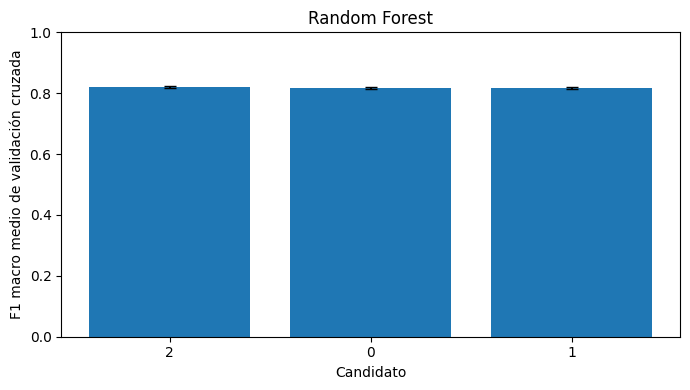

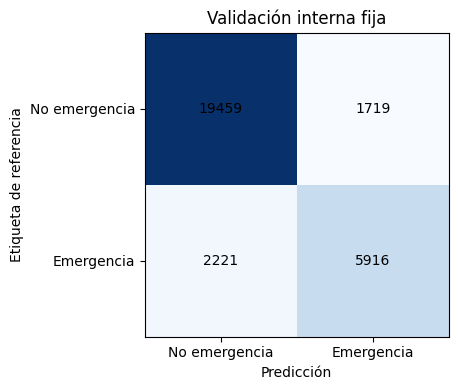

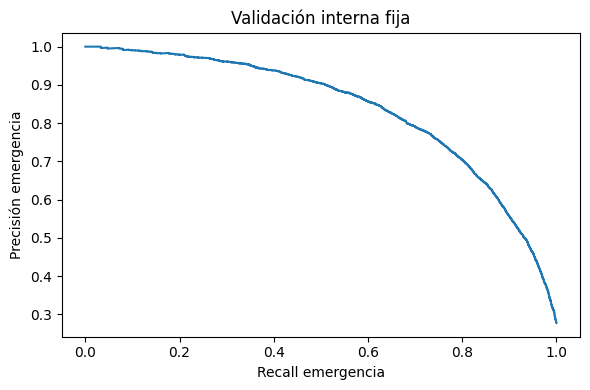

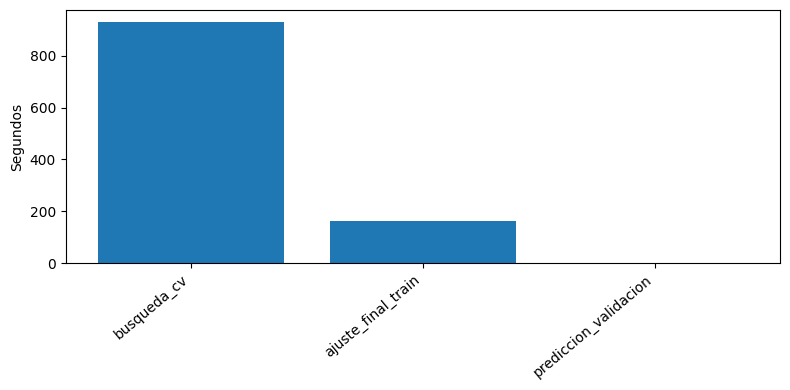

04:22:56 | training_complete | model=02_random_forest_v2 | selected_params={'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt'} | threshold=0.49658


,n,accuracy,precision_emergency,recall_emergency,f1_macro,fpr,roc_auc,average_precision,tn,fp,fn,tp,threshold
0,29315,0.865598,0.774853,0.727049,0.829129,0.081169,0.911667,0.836286,19459,1719,2221,5916,0.496581


RESULTADOS PARA DEVOLVER: /kaggle/working/entrenamiento/02_random_forest_v2/20261010T034849_698618Z_resultados.zip
MODELOS PARA CONSERVAR: /kaggle/working/entrenamiento/02_random_forest_v2/20261010T034849_698618Z_modelos.zip
LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds: a78aa85fad02f6ec74c26ecfac6898b42c8360f2cd6dd64c6a6a682255e8dfb4
04:23:02 | stage_end | stage=tabular_computation | seconds=35.483


In [13]:
with stage_guard('tabular_computation'):
    # Cronometra inferencia con características ya calculadas. No es latencia extremo a extremo.
    for _ in range(CFG['latency_warmup']): scores_of(FINAL,X_VALID[:1])
    latencies=[]
    for _ in range(CFG['latency_repeats']):
        start=time.perf_counter(); scores_of(FINAL,X_VALID[:1]); latencies.append((time.perf_counter()-start)*1000)
    batch=X_VALID[:min(len(X_VALID),CFG['throughput_batch'])]
    start=time.perf_counter(); scores_of(FINAL,batch); batch_seconds=time.perf_counter()-start
    save_table('latency.csv',[{'scope':'CPU; one precomputed feature vector; includes pipeline scaling',
        'warmup':CFG['latency_warmup'],'repetitions':len(latencies),'p50_ms':np.percentile(latencies,50),
        'p95_ms':np.percentile(latencies,95),'batch_n':len(batch),'batch_seconds':batch_seconds,
        'batch_segments_per_second':len(batch)/batch_seconds,
        'process_peak_rss_mib':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024,
        'model_file_mib':(OUT/'models'/'pipeline.joblib').stat().st_size/1024**2}])
    make_reports(FINAL_SCORES,OOF,THRESHOLD,SELECTED,SUMMARY,runtime_rows)


## Devolución y lectura de logs
Devuelve la notebook ejecutada y `*_resultados.zip`. Conserva `*_modelos.zip`. Si hay error, devuelve el diagnóstico y las salidas de la celda.

`logs/training.log` es legible; `logs/events.jsonl` registra eventos estructurados; `tables/cv_results.csv` contiene folds y, en redes, `tables/epoch_history.csv` contiene épocas. TensorBoard escribe en `logs/tensorboard/` si está disponible. En una celda posterior puedes ejecutar `%load_ext tensorboard` y `%tensorboard --logdir <ruta logs/tensorboard>`.

Las métricas de búsqueda y del umbral OOF son evidencia de desarrollo, no una estimación independiente después de seleccionar. No se concluye desempeño externo ni tiempo real extremo a extremo.

Referencias: [entrenamiento PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html), [TensorBoard](https://docs.pytorch.org/docs/stable/tensorboard.html), [registro de CV sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).